# DS_Day01_41 — OTT: Why Do Users Stop Watching?
**Industry:** Streaming & OTT | **Algorithm:** Random Forest (predict `Retention_Status`)

**Workflow:** Load → Clean → Feature engineering → EDA → 4 visualisations → Behaviour patterns → Early-warning signs → Random Forest → Insights & Strategies

> Run cells top to bottom (Runtime → Run all).

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", 50)

In [2]:
USE_SAMPLE_DATA = True   # <-- set False to upload your own CSV

GENRES = ["Drama","Comedy","Action","Thriller","Documentary","Romance","Sci-Fi","Kids"]

def make_sample_data(n=1200, seed=42, dirty=True):
    rng = np.random.default_rng(seed)
    plan = rng.choice(["Basic","Standard","Premium"], n, p=[.40,.35,.25])
    plan_eff = pd.Series(plan).map({"Basic":-0.35,"Standard":0.0,"Premium":0.4}).values
    e = rng.normal(0, 1, n) + plan_eff                                   # latent engagement
    titles = np.clip(np.round(5 + 2.6*e + rng.normal(0,1,n)), 1, 10).astype(int)
    div = np.clip(np.round(2.6 + 1.3*e + rng.normal(0,.8,n)), 1, 6).astype(int)
    div = np.minimum(div, titles)
    dur = np.clip(38 + 13*e + rng.normal(0, 8, n), 5, 150).round(0)
    inact = np.clip(np.round(np.exp(1.7 - 0.55*e + rng.normal(0, .55, n))), 0, 60).astype(int)
    prim = rng.choice(GENRES, n, p=[.22,.18,.16,.12,.08,.10,.08,.06])
    hist = []
    for i in range(n):
        pool = [prim[i]] + list(rng.choice([g for g in GENRES if g != prim[i]], div[i]-1, replace=False))
        seq = pool + list(rng.choice(pool, titles[i]-len(pool))) if titles[i] > len(pool) else pool
        rng.shuffle(seq); hist.append(";".join(seq))
    logit = (-1.7 + 0.13*inact - 0.035*(dur-38) - 0.35*(div-2.6) - 0.15*(titles-5)
             + pd.Series(plan).map({"Basic":0.45,"Standard":0.0,"Premium":-0.45}).values)
    churn = rng.random(n) < 1/(1+np.exp(-logit))
    df = pd.DataFrame({"User_ID": [f"U{1000+i}" for i in range(n)], "Viewing_History": hist,
                       "Session_Duration": dur, "Content_Genre": prim, "Subscription_Plan": plan,
                       "Inactivity_Period": inact, "Retention_Status": np.where(churn, "Churned", "Retained")})
    if dirty:  # inject messy data so the cleaning step has work to do
        k = max(3, n // 40)
        df.loc[rng.choice(n, k, replace=False), "Session_Duration"] = np.nan
        df.loc[rng.choice(n, k, replace=False), "Inactivity_Period"] = np.nan
        df.loc[rng.choice(n, k//2, replace=False), "Session_Duration"] = -5
        df.loc[rng.choice(n, k//2, replace=False), "Subscription_Plan"] = "  premium "
        df.loc[rng.choice(n, k//2, replace=False), "Retention_Status"] = "churned"
        df = pd.concat([df, df.sample(k, random_state=1)], ignore_index=True)
    return df

if USE_SAMPLE_DATA:
    raw = make_sample_data()
    print("Using SAMPLE data.")
else:
    from google.colab import files
    up = files.upload()
    raw = pd.read_csv(list(up.keys())[0])
print("Shape:", raw.shape)
raw.head()

Using SAMPLE data.
Shape: (1230, 7)


,User_ID,Viewing_History,Session_Duration,Content_Genre,Subscription_Plan,Inactivity_Period,Retention_Status
0,U1000,Action;Comedy;Action;Sci-Fi;Action;Comedy,40.0,Sci-Fi,Premium,22.0,Retained
1,U1001,Kids;Drama;Documentary;Kids,30.0,Drama,Standard,17.0,Retained
2,U1002,Romance;Documentary;Action;Documentary;Action;...,67.0,Comedy,Premium,1.0,Retained
3,U1003,Comedy;Kids;Romance;Romance;Kids;Action;Comedy...,70.0,Action,Standard,2.0,Retained
4,U1004,Comedy;Documentary,16.0,Comedy,Basic,9.0,Churned


## 2. Clean & validate

In [3]:
df = raw.copy()
print("--- BEFORE ---")
print("Missing:\n", df.isna().sum()); print("Duplicate rows:", df.duplicated().sum(),
      "| Duplicate User_IDs:", df.duplicated("User_ID").sum())

# 1) Duplicates
df = df.drop_duplicates().drop_duplicates("User_ID", keep="first")

# 2) Standardise text categories
for c in ["Content_Genre","Subscription_Plan","Retention_Status"]:
    df[c] = df[c].astype("string").str.strip().str.title()
df["Retention_Status"] = df["Retention_Status"].replace({"Active":"Retained","Stayed":"Retained","Yes":"Retained",
                                                          "Cancelled":"Churned","Canceled":"Churned","Inactive":"Churned","No":"Churned"})
df = df[df["Retention_Status"].isin(["Retained","Churned"])]          # target must be valid

# 3) Impossible values -> missing, then fill numerics with the median of the user's plan
for c in ["Session_Duration","Inactivity_Period"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    df.loc[df[c] < 0, c] = np.nan
    df[c] = df.groupby("Subscription_Plan")[c].transform(lambda s: s.fillna(s.median()))
    df[c] = df[c].fillna(df[c].median())

# 4) Categorical gaps
df["Viewing_History"] = df["Viewing_History"].fillna("")
df["Content_Genre"] = df["Content_Genre"].fillna("Unknown")
df["Subscription_Plan"] = df["Subscription_Plan"].fillna(df["Subscription_Plan"].mode()[0])

# 5) Outliers: cap extreme durations at 99th percentile (winsorise, don't delete users)
cap = df["Session_Duration"].quantile(.99); df["Session_Duration"] = df["Session_Duration"].clip(upper=cap)

df = df.reset_index(drop=True)
print("\n--- AFTER ---"); print("Missing:", df.isna().sum().sum(), "| Shape:", df.shape)
print(df["Retention_Status"].value_counts())

--- BEFORE ---
Missing:
 User_ID               0
Viewing_History       0
Session_Duration     30
Content_Genre         0
Subscription_Plan     0
Inactivity_Period    31
Retention_Status      0
dtype: int64
Duplicate rows: 30 | Duplicate User_IDs: 30

--- AFTER ---
Missing: 0 | Shape: (1200, 7)
Retention_Status
Retained    710
Churned     490
Name: count, dtype: Int64


## 3. Feature engineering
- `Recent_Titles` = number of titles in `Viewing_History`
- `Genre_Diversity` = number of *different* genres watched (content diversity)
- `Diversity_Level` = Low / Medium / High
- `Churned` = 1 if churned (model target)

In [4]:
parsed = df["Viewing_History"].str.split(";").apply(lambda l: [g.strip().title() for g in l if g.strip()])
df["Recent_Titles"] = parsed.apply(len)
df["Genre_Diversity"] = parsed.apply(lambda l: len(set(l)))
df["Diversity_Level"] = pd.cut(df["Genre_Diversity"], [0,1,3,100], labels=["Low (1 genre)","Medium (2-3)","High (4+)"])
df["Churned"] = (df["Retention_Status"] == "Churned").astype(int)
df["Inactivity_Band"] = pd.cut(df["Inactivity_Period"], [-1,3,7,14,30,1000],
                               labels=["0-3d","4-7d","8-14d","15-30d","30d+"])
df.head()

,User_ID,Viewing_History,Session_Duration,Content_Genre,Subscription_Plan,Inactivity_Period,Retention_Status,Recent_Titles,Genre_Diversity,Diversity_Level,Churned,Inactivity_Band
0,U1000,Action;Comedy;Action;Sci-Fi;Action;Comedy,40.0,Sci-Fi,Premium,22.0,Retained,6,3,Medium (2-3),0,15-30d
1,U1001,Kids;Drama;Documentary;Kids,30.0,Drama,Standard,17.0,Retained,4,3,Medium (2-3),0,15-30d
2,U1002,Romance;Documentary;Action;Documentary;Action;...,67.0,Comedy,Premium,1.0,Retained,10,6,High (4+),0,0-3d
3,U1003,Comedy;Kids;Romance;Romance;Kids;Action;Comedy...,70.0,Action,Standard,2.0,Retained,9,4,High (4+),0,0-3d
4,U1004,Comedy;Documentary,16.0,Comedy,Basic,9.0,Churned,2,2,Medium (2-3),1,8-14d


## 4. Exploratory data analysis

In [5]:
num = ["Session_Duration","Recent_Titles","Genre_Diversity","Inactivity_Period"]
display(df[num].describe().round(2))
print("Overall churn rate: {:.1%}".format(df["Churned"].mean()))
display(df.groupby("Retention_Status")[num].mean().round(2))
print(df["Subscription_Plan"].value_counts(), "\n"); print(df["Content_Genre"].value_counts())

,Session_Duration,Recent_Titles,Genre_Diversity,Inactivity_Period
count,1200.00,1200.00,1200.00,1200.00
mean,36.94,4.86,2.60,8.09
std,15.26,2.61,1.37,7.62
min,5.00,1.00,1.00,0.00
25%,27.00,3.00,1.00,3.00
50%,37.00,5.00,2.00,6.00
75%,48.00,7.00,4.00,10.00
max,71.01,10.00,6.00,60.00


Overall churn rate: 40.8%


,Session_Duration,Recent_Titles,Genre_Diversity,Inactivity_Period
Retention_Status,,,,
Churned,26.90,3.07,1.70,12.53
Retained,43.87,6.10,3.22,5.02


Subscription_Plan
Basic       472
Standard    405
Premium     323
Name: count, dtype: Int64 

Content_Genre
Drama          255
Comedy         220
Action         183
Thriller       141
Romance        120
Sci-Fi          98
Documentary     94
Kids            89
Name: count, dtype: Int64


## 5. Viewing behaviour patterns (clustering) & average watch time by segment

In [6]:
X = StandardScaler().fit_transform(df[num])
km = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X)
df["Cluster"] = km.labels_
prof = df.groupby("Cluster")[num].mean()
names = {}
fading = prof["Inactivity_Period"].idxmax(); names[fading] = "Fading / At-risk"
rest = prof.drop(fading)
binge = (rest["Session_Duration"]/rest["Session_Duration"].mean() + rest["Recent_Titles"]/rest["Recent_Titles"].mean()).idxmax()
names[binge] = "Engaged Binge-watchers"
names[[c for c in prof.index if c not in names][0]] = "Casual Viewers"
df["Segment"] = df["Cluster"].map(names)

seg = df.groupby("Segment").agg(Users=("User_ID","count"), Avg_Session_Min=("Session_Duration","mean"),
        Avg_Titles=("Recent_Titles","mean"), Avg_Diversity=("Genre_Diversity","mean"),
        Avg_Inactive_Days=("Inactivity_Period","mean"), Churn_Rate=("Churned","mean")).round(2)
print("Behaviour segments:"); display(seg)
print("Average watch time (min/session) by SUBSCRIPTION PLAN:"); display(df.groupby("Subscription_Plan")["Session_Duration"].mean().round(1))
print("Average watch time by PRIMARY GENRE:"); display(df.groupby("Content_Genre")["Session_Duration"].mean().sort_values(ascending=False).round(1))
print("Average watch time by RETENTION STATUS:"); display(df.groupby("Retention_Status")["Session_Duration"].mean().round(1))

Behaviour segments:


,Users,Avg_Session_Min,Avg_Titles,Avg_Diversity,Avg_Inactive_Days,Churn_Rate
Segment,,,,,,
Casual Viewers,531,36.93,4.67,2.38,6.43,0.37
Engaged Binge-watchers,352,52.63,7.89,4.21,3.53,0.07
Fading / At-risk,317,19.53,1.83,1.17,15.92,0.85


Average watch time (min/session) by SUBSCRIPTION PLAN:


,Session_Duration
Subscription_Plan,
Basic,32.4
Premium,42.0
Standard,38.2


Average watch time by PRIMARY GENRE:


,Session_Duration
Content_Genre,
Action,38.3
Drama,37.0
Romance,37.0
Thriller,36.8
Kids,36.7
Documentary,36.6
Comedy,36.4
Sci-Fi,36.4


Average watch time by RETENTION STATUS:


,Session_Duration
Retention_Status,
Churned,26.9
Retained,43.9


## 6. Visualisations (the 4 required)

### Viz 1 — Average watch time by customer segment

/tmp/ipykernel_621/2514133262.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Segment", y="Session_Duration", order=order, ax=ax[0], errorbar=None, palette="viridis")


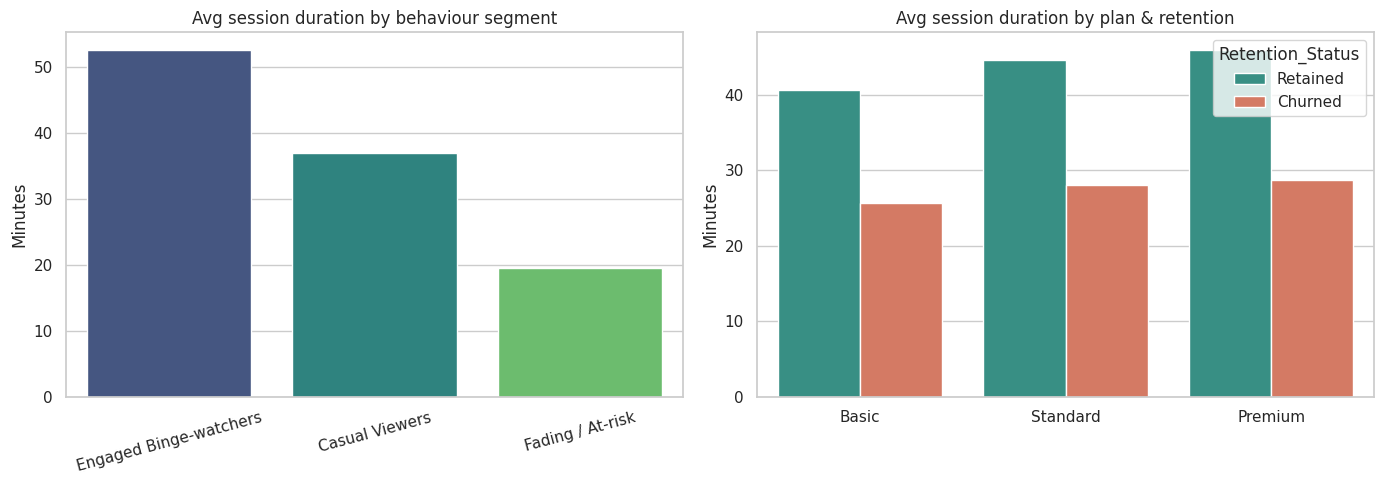

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
order = ["Engaged Binge-watchers","Casual Viewers","Fading / At-risk"]
sns.barplot(data=df, x="Segment", y="Session_Duration", order=order, ax=ax[0], errorbar=None, palette="viridis")
ax[0].set_title("Avg session duration by behaviour segment"); ax[0].set_xlabel(""); ax[0].set_ylabel("Minutes")
ax[0].tick_params(axis="x", rotation=15)
sns.barplot(data=df, x="Subscription_Plan", y="Session_Duration", hue="Retention_Status",
            order=["Basic","Standard","Premium"], ax=ax[1], errorbar=None, palette={"Retained":"#2a9d8f","Churned":"#e76f51"})
ax[1].set_title("Avg session duration by plan & retention"); ax[1].set_xlabel(""); ax[1].set_ylabel("Minutes")
plt.tight_layout(); plt.show()

### Viz 2 — Early sign of disengagement: churn rate by inactivity

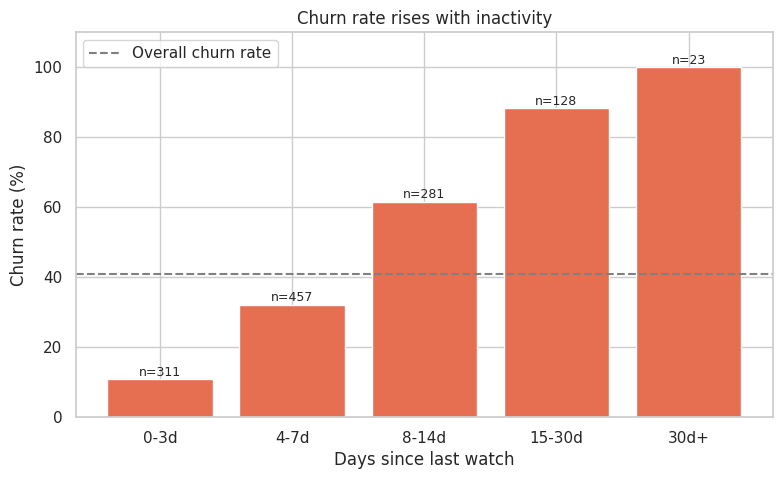

In [8]:
ib = df.groupby("Inactivity_Band", observed=True).agg(Users=("Churned","size"), Churn_Rate=("Churned","mean"))
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(ib.index.astype(str), ib["Churn_Rate"]*100, color="#e76f51")
for b, n in zip(bars, ib["Users"]): ax.text(b.get_x()+b.get_width()/2, b.get_height()+1, f"n={n}", ha="center", fontsize=9)
ax.axhline(df["Churned"].mean()*100, ls="--", color="gray", label="Overall churn rate")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Days since last watch"); ax.set_ylim(0, 110)
ax.set_title("Churn rate rises with inactivity"); ax.legend(); plt.show()

### Viz 3 — Does content diversity influence engagement?

/tmp/ipykernel_621/2034331392.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Diversity_Level", y="Session_Duration", ax=ax[0], palette="Blues")


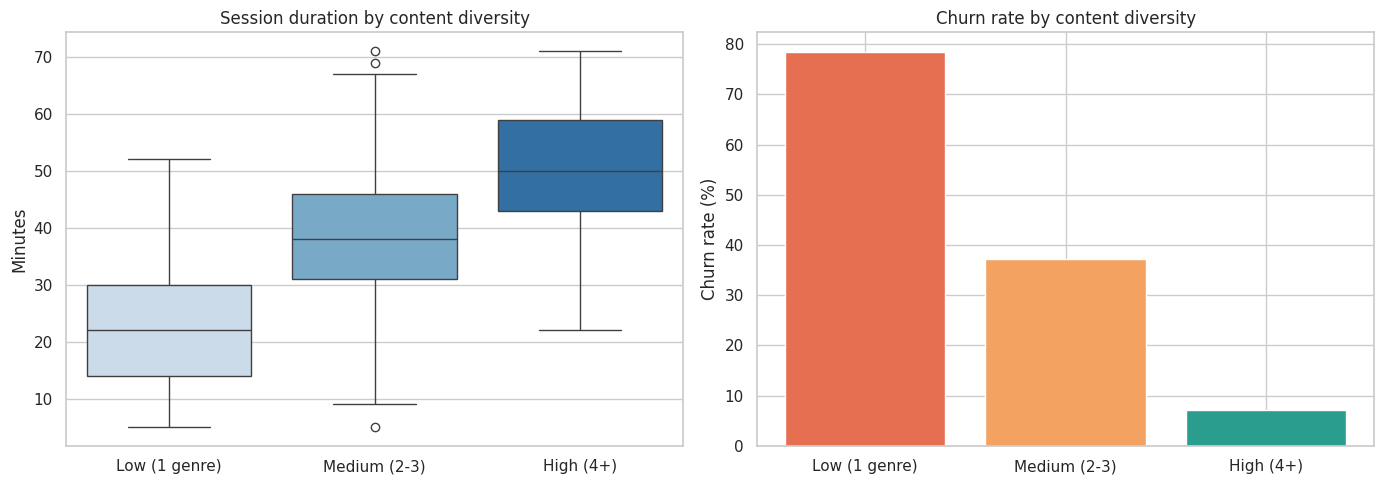

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="Diversity_Level", y="Session_Duration", ax=ax[0], palette="Blues")
ax[0].set_title("Session duration by content diversity"); ax[0].set_xlabel(""); ax[0].set_ylabel("Minutes")
dl = df.groupby("Diversity_Level", observed=True)["Churned"].mean()*100
ax[1].bar(dl.index.astype(str), dl.values, color=["#e76f51","#f4a261","#2a9d8f"])
ax[1].set_title("Churn rate by content diversity"); ax[1].set_ylabel("Churn rate (%)")
plt.tight_layout(); plt.show()

### Viz 4 — Viewing behaviour patterns (clusters)

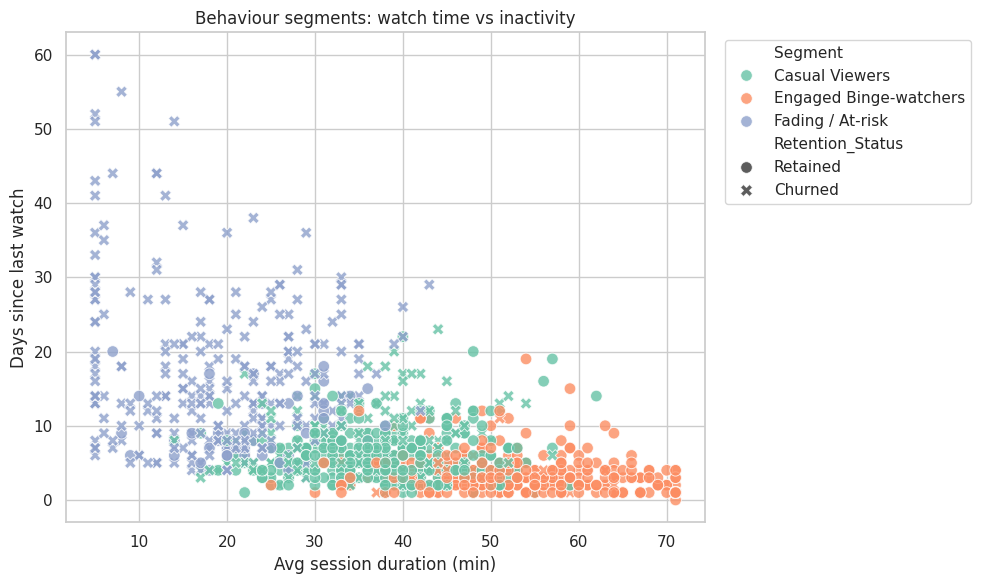

In [11]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Session_Duration", y="Inactivity_Period", hue="Segment", style="Retention_Status",
                s=70, alpha=.8, palette="Set2", markers={"Retained":"o","Churned":"X"})
plt.title("Behaviour segments: watch time vs inactivity"); plt.xlabel("Avg session duration (min)")
plt.ylabel("Days since last watch"); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

## 7. Statistical checks & early-warning thresholds

In [12]:
# Diversity vs engagement and churn
r, p = stats.spearmanr(df["Genre_Diversity"], df["Session_Duration"])
print(f"Diversity vs session duration: Spearman rho={r:.3f}, p={p:.4g}")
a, b = df.loc[df.Churned==1, "Genre_Diversity"], df.loc[df.Churned==0, "Genre_Diversity"]
u, p = stats.mannwhitneyu(a, b); print(f"Diversity churned vs retained: mean {a.mean():.2f} vs {b.mean():.2f}, Mann-Whitney p={p:.4g}")
# Plan vs churn
ct = pd.crosstab(df["Subscription_Plan"], df["Churned"]); chi2, p, _, _ = stats.chi2_contingency(ct)
print(f"Plan vs churn: chi2={chi2:.2f}, p={p:.4g} (small samples -> interpret cautiously)")
# Plan comparison table
display(df.groupby("Subscription_Plan").agg(Users=("User_ID","count"), Avg_Session_Min=("Session_Duration","mean"),
        Avg_Diversity=("Genre_Diversity","mean"), Avg_Inactive_Days=("Inactivity_Period","mean"),
        Churn_Rate=("Churned","mean")).round(2))

# Early-warning: if we flag users inactive >= X days, how many churners do we catch?
rows = []
for t in [3, 5, 7, 10, 14, 21]:
    f = df["Inactivity_Period"] >= t
    rows.append([t, f.sum(), df.loc[f,"Churned"].mean() if f.sum() else np.nan,
                 df.loc[f,"Churned"].sum()/df["Churned"].sum()])
display(pd.DataFrame(rows, columns=["Inactive_>=_days","Users_flagged","Churn_rate_of_flagged","Share_of_all_churners_caught"]).round(2))

Diversity vs session duration: Spearman rho=0.714, p=5.674e-188
Diversity churned vs retained: mean 1.70 vs 3.22, Mann-Whitney p=3.786e-84
Plan vs churn: chi2=80.86, p=2.766e-18 (small samples -> interpret cautiously)


,Users,Avg_Session_Min,Avg_Diversity,Avg_Inactive_Days,Churn_Rate
Subscription_Plan,,,,,
Basic,472,32.43,2.25,9.97,0.55
Premium,323,42.01,3.02,5.96,0.23
Standard,405,38.15,2.66,7.59,0.39


,Inactive_>=_days,Users_flagged,Churn_rate_of_flagged,Share_of_all_churners_caught
0,3,1027,0.46,0.97
1,5,748,0.56,0.86
2,7,521,0.66,0.70
3,10,315,0.79,0.51
4,14,185,0.89,0.34
5,21,81,0.99,0.16


## 8. Random Forest model
**Target:** `Retention_Status` (Churned = 1) | **Features:** session duration, titles, genre diversity, inactivity, plan, primary genre.

With small datasets a single split is noisy, so we report **5-fold stratified cross-validation** (reliable) *and* a hold-out test set (for the confusion matrix).

In [13]:
features = ["Session_Duration","Recent_Titles","Genre_Diversity","Inactivity_Period","Subscription_Plan","Content_Genre"]
Xm = pd.get_dummies(df[features], columns=["Subscription_Plan","Content_Genre"], drop_first=True).astype(float)
y = df["Churned"]

rf = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=3, class_weight="balanced", random_state=42)

# Cross-validation
cv = cross_validate(rf, Xm, y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                    scoring=["accuracy","precision","recall","f1","roc_auc"])
print("5-fold CV results (mean +/- std):")
for m in ["accuracy","precision","recall","f1","roc_auc"]:
    print(f"  {m:10s}: {cv['test_'+m].mean():.3f} +/- {cv['test_'+m].std():.3f}")
print(f"  Baseline (always predict majority): {max(y.mean(), 1-y.mean()):.3f}")

# Hold-out test
X_tr, X_te, y_tr, y_te = train_test_split(Xm, y, test_size=0.25, stratify=y, random_state=42)
rf.fit(X_tr, y_tr); pred = rf.predict(X_te); proba = rf.predict_proba(X_te)[:,1]
print(f"\nHold-out ({len(y_te)} users): acc={accuracy_score(y_te,pred):.3f}, precision={precision_score(y_te,pred):.3f}, "
      f"recall={recall_score(y_te,pred):.3f}, F1={f1_score(y_te,pred):.3f}, AUC={roc_auc_score(y_te,proba):.3f}")
print(classification_report(y_te, pred, target_names=["Retained","Churned"]))

5-fold CV results (mean +/- std):
  accuracy  : 0.797 +/- 0.019
  precision : 0.749 +/- 0.042
  recall    : 0.763 +/- 0.048
  f1        : 0.754 +/- 0.019
  roc_auc   : 0.877 +/- 0.017
  Baseline (always predict majority): 0.592

Hold-out (300 users): acc=0.830, precision=0.793, recall=0.787, F1=0.790, AUC=0.894
              precision    recall  f1-score   support

    Retained       0.85      0.86      0.86       178
     Churned       0.79      0.79      0.79       122

    accuracy                           0.83       300
   macro avg       0.82      0.82      0.82       300
weighted avg       0.83      0.83      0.83       300



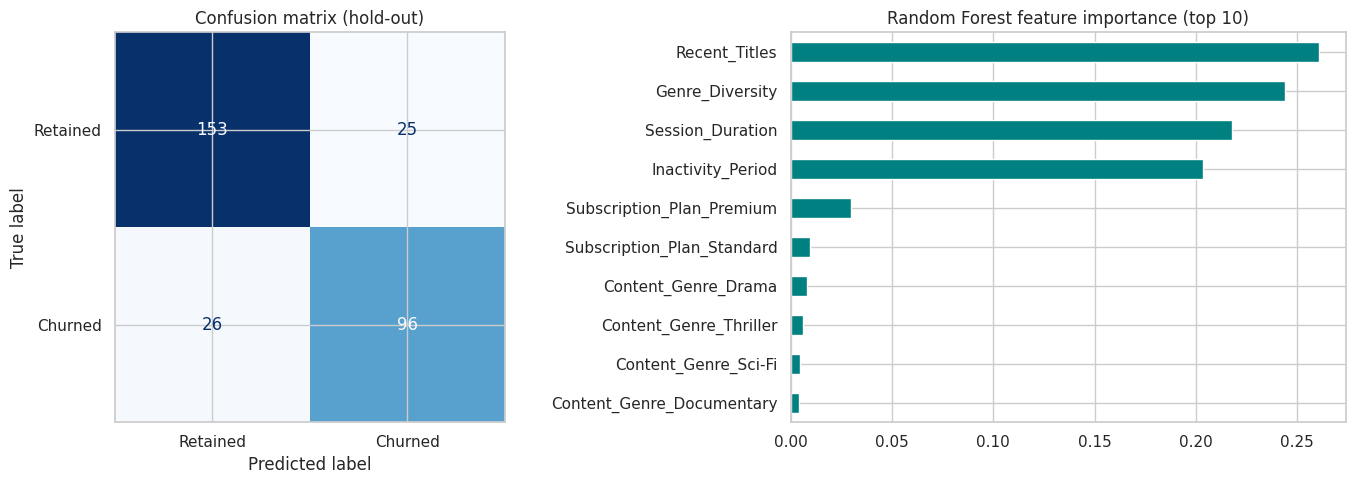

,Permutation importance (AUC drop)
Inactivity_Period,0.033
Session_Duration,0.032
Genre_Diversity,0.029
Recent_Titles,0.026
Subscription_Plan_Premium,0.009
Content_Genre_Drama,0.001


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Retained","Churned"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (hold-out)")
imp = pd.Series(rf.feature_importances_, index=Xm.columns).sort_values().tail(10)
imp.plot.barh(ax=ax[1], color="teal"); ax[1].set_title("Random Forest feature importance (top 10)")
plt.tight_layout(); plt.show()

perm = permutation_importance(rf, X_te, y_te, n_repeats=20, random_state=42, scoring="roc_auc")
display(pd.Series(perm.importances_mean, index=Xm.columns).sort_values(ascending=False).head(6).round(3).rename("Permutation importance (AUC drop)"))


## 9. Strategies to improve engagement
| Signal (from analysis) | Strategy | Metric to track |
|---|---|---|
| Inactivity crosses the early-warning threshold | Automated "We miss you" push/email with personalised picks; run before day ___ | Re-activation rate |
| Low content diversity (1 genre) | Cross-genre recommendations ("if you liked X, try Y"), curated collections | Genres per user, churn by diversity |
| Short sessions / fading segment | Autoplay next episode, shorter-format content, reminders for unfinished shows | Avg session minutes |
| High-churn plan (likely Basic) | Free trial of premium features, discounted annual upgrade, bundle offers | Plan churn rate, upgrade rate |
| Model flags high churn risk | Weekly risk score list to retention team; targeted offers for top-risk users | Precision of offers, saved subscribers |
| Ongoing | Retrain the model monthly; A/B test each strategy | Lift vs control |